# Clean-Hour E11: a decision-focused Transformer (PyTorch, GPU)

**Question:** our production model (gradient boosting) predicts each hour on its own. Can a neural network that sees all 76 future hours at once, and is trained to *choose* the cleanest 4-hour window instead of only predicting numbers, pick cleaner hours for a Northern Virginia household or a Loudoun data center?

**Fair test (fixed before scoring 2026):** train 2023 to mid-2025, pick epochs on late 2025, refit on 2023-2025, score once on every complete 2026 day. Same baselines (persistence = tomorrow equals today, hour-of-week average, perfect hindsight) and the same 95% block bootstrap as the main results.

**Kill rule:** WIN only if the decision Transformer beats the production model with an interval below zero at both 24 h and 72 h in at least 3 of 5 grids.

**Before you start:** Runtime > Change runtime type > **T4 GPU**. Then Runtime > **Run all**. The first cell downloads about 1 GB of public grid data (10-20 min).

In [7]:
!git clone -q -b exp/torch-transformer https://github.com/Harshal623/clean-hour
%cd clean-hour
!pip -q install -r requirements.txt
import torch; print('GPU:', torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else '')

/content/clean-hour/clean-hour
GPU: True Tesla T4


## 1. Download and cache the public data (EIA-930, Energy-Charts, NESO, Open-Meteo)

In [8]:
!python -I src/grids.py

downloading https://www.eia.gov/electricity/gridmonitor/sixMonthFiles/EIA930_BALANCE_2023_Jan_Jun.csv
downloading https://www.eia.gov/electricity/gridmonitor/sixMonthFiles/EIA930_BALANCE_2023_Jul_Dec.csv
downloading https://www.eia.gov/electricity/gridmonitor/sixMonthFiles/EIA930_BALANCE_2024_Jan_Jun.csv
downloading https://www.eia.gov/electricity/gridmonitor/sixMonthFiles/EIA930_BALANCE_2024_Jul_Dec.csv
downloading https://www.eia.gov/electricity/gridmonitor/sixMonthFiles/EIA930_BALANCE_2025_Jan_Jun.csv
downloading https://www.eia.gov/electricity/gridmonitor/sixMonthFiles/EIA930_BALANCE_2025_Jul_Dec.csv
downloading https://www.eia.gov/electricity/gridmonitor/sixMonthFiles/EIA930_BALANCE_2026_Jan_Jun.csv
downloading https://www.eia.gov/electricity/gridmonitor/sixMonthFiles/EIA930_BALANCE_2026_Jul_Dec.csv
DE (33913, 1) 2022-12-31 23:00:00 -> 2026-11-13 23:00:00
GB (33912, 2) 2023-01-01 00:00:00 -> 2026-11-13 23:00:00
downloading 2023 Jan_Jun
downloading 2023 Jul_Dec
downloading 2024 Jan

## 2. Train both Transformers on 2023-2025 and score them on 2026
Prints each grid as it finishes, then the verdict.

In [9]:
!python -I -W ignore src/experiments/torch_transformer/run.py

device: cuda | torch 2.14.1+cu130

=== Virginia
  transformer_mse: {'variant': 'transformer_mse', 'epochs_per_seed': [35, 27, 21], 'epochs_used': 27, 'val_regret_24h_g_per_kwh': [3.83, 3.66, 3.71], 'seconds': 30.4}
  transformer_decision: {'variant': 'transformer_decision', 'epochs_per_seed': [18, 9, 15], 'epochs_used': 15, 'val_regret_24h_g_per_kwh': [3.81, 3.29, 3.13], 'seconds': 20.9}
  failure check (24 h): worst days ['2026-09-27 (40 g/kWh above the best window)', '2026-02-18 (39 g/kWh above the best window)', '2026-01-09 (39 g/kWh above the best window)']; advice worse than midnight on 8.4% of days
 slip_h                             method  g_per_kwh  pct_of_perfect_saving  minus_gbm  minus_gbm_lo  minus_gbm_hi  hourly_mae
     24                        persistence     330.59                  79.38       1.42          0.11          2.75       21.45
     24                        climatology     343.03                  36.05      13.85         11.67         16.33       29.72
    

## 3. Results: share of the best possible saving captured (higher is better)

In [10]:
import pandas as pd, json
S = pd.read_csv('results/experiments/torch_transformer/summary.csv')
for slip in [24, 72]:
    print(f'\n{slip} h of slack, % of the best possible saving')
    print(S[S.slip_h == slip].pivot(index='region', columns='method', values='pct_of_perfect_saving').round(1).to_string())
print('\nTransformer (decision) minus production model, g/kWh, 95% interval (negative = Transformer better):')
t = S[S.method == 'transformer_decision'][['region','slip_h','minus_gbm','minus_gbm_lo','minus_gbm_hi','hourly_mae']]
print(t.round(2).to_string(index=False))
log = json.load(open('results/experiments/torch_transformer/run_log.json'))
print('\nVERDICT:', log['verdict'], '| wins:', log['wins'])
for g in log['grids']: print(g['grid'], 'worst days:', g['worst_days_24h'])


24 h of slack, % of the best possible saving
method         blend (gbm + transformer_decision)  climatology  gbm (production)  persistence  transformer_decision  transformer_mse
region                                                                                                                              
California                                   98.5         93.0              98.3         97.6                  98.5             98.3
Germany                                      96.2         95.0              95.3         92.6                  96.5             96.5
Great Britain                                84.3         10.9              82.0         63.5                  82.2             85.0
Texas                                        93.8         91.4              92.7         91.9                  92.5             94.6
Virginia                                     87.5         36.1              84.3         79.4                  87.9             89.0

72 h of slack, % of th

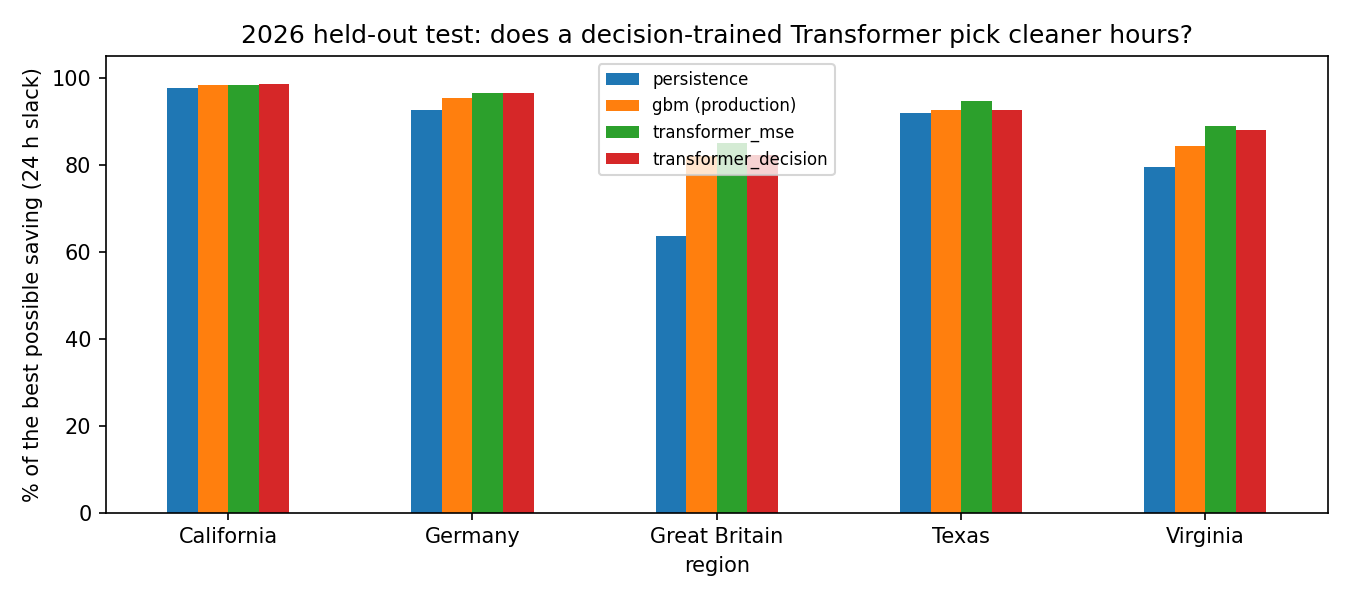

In [11]:
from IPython.display import Image
Image('results/experiments/torch_transformer/capture_24h.png')

## 4. Save your results
1. Run the next cell and download `torch_results.zip` (send it to the team / Claude so the numbers go into the write-up).
2. **File > Save a copy in GitHub** > repo `Harshal623/clean-hour`, branch `exp/torch-transformer`, path `src/experiments/torch_transformer/colab.ipynb`. That puts this notebook, with outputs, where judges can see it.

In [ ]:
!zip -qr torch_results.zip results/experiments/torch_transformer
from google.colab import files
files.download('torch_results.zip')